In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Load dataset and inspect shape, dtypes, and missing values
df = pd.read_csv('retail_sales_dataset.csv')
print("Dataset Shape:", df.shape)
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())
df.head()

Dataset Shape: (1000, 9)

Data Types:
 Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Missing Values:
 Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


### Observation — Initial Data Inspection
* The dataset contains **1,000 rows and 9 columns**.
* There are **0 missing (null) values** across all columns, meaning the dataset is complete and ready for analysis.
* Numerical columns include `Age`, `Quantity`, `Price per Unit`, and `Total Amount`, while `Date`, `Gender`, and `Product Category` are stored as object/string types.


In [2]:
# Descriptive statistics: mean, median, standard deviation, and mode
desc_stats = df.describe().T
desc_stats['median'] = df.median(numeric_only=True)
print("Descriptive Statistics:\n", desc_stats[['mean', 'median', 'std', 'min', 'max']])

print("\nMode values:\n", df.mode().iloc[0])

Descriptive Statistics:
                    mean  median         std   min     max
Transaction ID  500.500   500.5  288.819436   1.0  1000.0
Age              41.392    42.0   13.681430  18.0    64.0
Quantity          2.514     3.0    1.132734   1.0     4.0
Price per Unit  179.890    50.0  189.681356  25.0   500.0
Total Amount    456.000   135.0  559.997632  25.0  2000.0

Mode values:
 Transaction ID               1
Date                2023-05-16
Customer ID            CUST001
Gender                  Female
Age                       43.0
Product Category      Clothing
Quantity                   4.0
Price per Unit            50.0
Total Amount              50.0
Name: 0, dtype: object


### Observation — Descriptive Statistics
* **Customer Age:** The average age is ~41.4 years (median: 42), ranging from 18 to 64 years.
* **Order Value (`Total Amount`):** The mean transaction value is 456, while the median is 135—indicating a right-skewed distribution driven by high-value electronics/clothing purchases.
* **Quantity & Pricing:** Customers purchase an average of ~2.5 units per order, with unit prices ranging from 25 to 500.

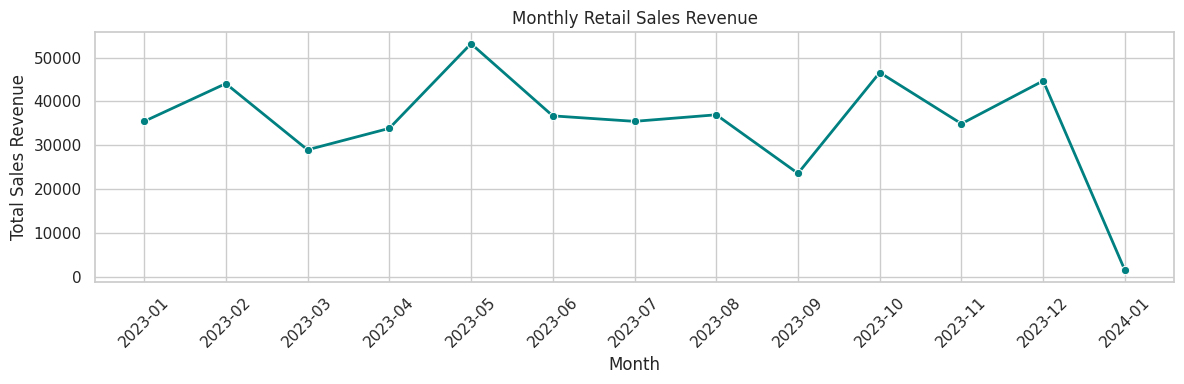

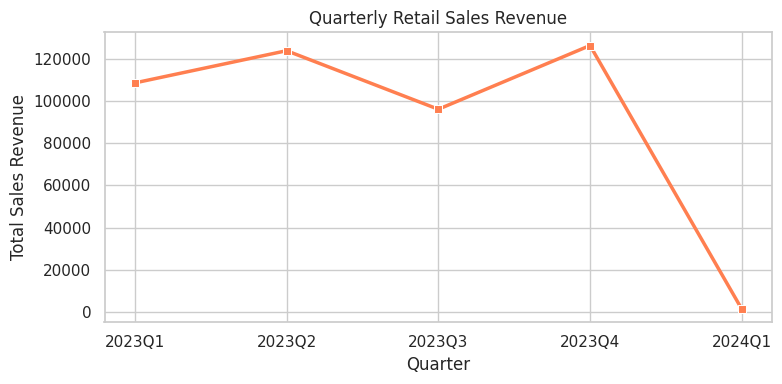

In [3]:
# Convert Date to datetime and extract Month and Quarter
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.to_period('M').astype(str)
df['Quarter'] = df['Date'].dt.to_period('Q').astype(str)

# Monthly Sales Trend
monthly_sales = df.groupby('Month')['Total Amount'].sum().reset_index()

plt.figure(figsize=(12, 4))
sns.lineplot(data=monthly_sales, x='Month', y='Total Amount', marker='o', color='teal', linewidth=2)
plt.title('Monthly Retail Sales Revenue')
plt.xlabel('Month')
plt.ylabel('Total Sales Revenue')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Quarterly Sales Trend
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum().reset_index()

plt.figure(figsize=(8, 4))
sns.lineplot(data=quarterly_sales, x='Quarter', y='Total Amount', marker='s', color='coral', linewidth=2.5)
plt.title('Quarterly Retail Sales Revenue')
plt.xlabel('Quarter')
plt.ylabel('Total Sales Revenue')
plt.tight_layout()
plt.show()

### Observation — Time Series Analysis
* **Monthly Trends:** Sales fluctuate across the year, showing clear peak months (such as May and October) and noticeable dips in months like March and September.
* **Quarterly Trends:** Revenue peaks in Q2 and Q4, reflecting seasonal shopping surges, while Q1 and Q3 show slightly softer overall performance.

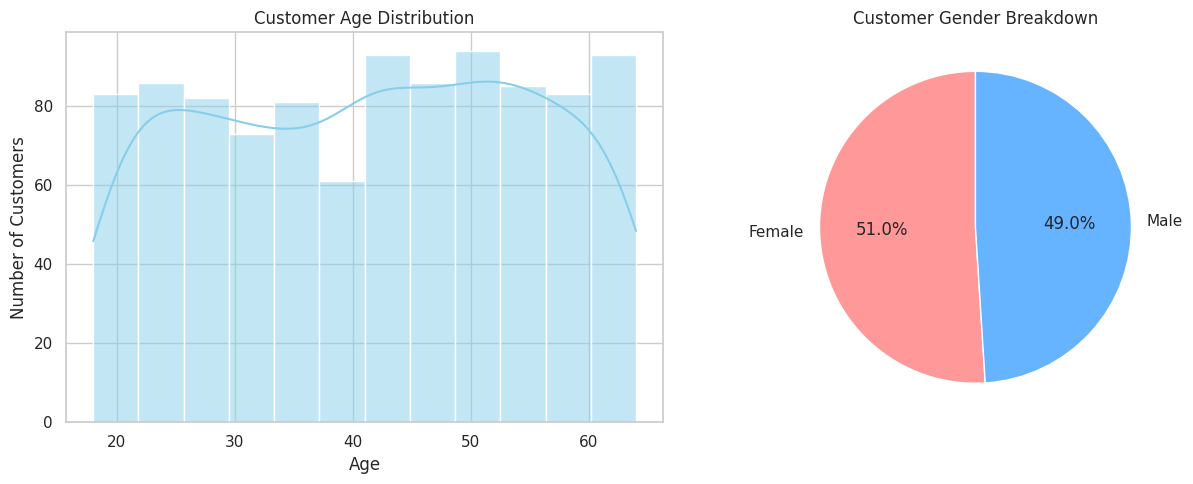

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Age Distribution
sns.histplot(df['Age'], bins=12, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Customer Age Distribution')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Number of Customers')

# Gender Breakdown
gender_counts = df['Gender'].value_counts()
axes[1].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90, colors=['#ff9999', '#66b3ff'])
axes[1].set_title('Customer Gender Breakdown')

plt.tight_layout()
plt.show()

### Observation — Customer Demographics
* **Gender Split:** The customer base is nearly balanced between Female (~51%) and Male (~49%) shoppers.
* **Age Distribution:** Customers are fairly evenly distributed across adult age brackets from 18 to 64, with slight concentrations in the early 20s, mid-40s, and early 60s.

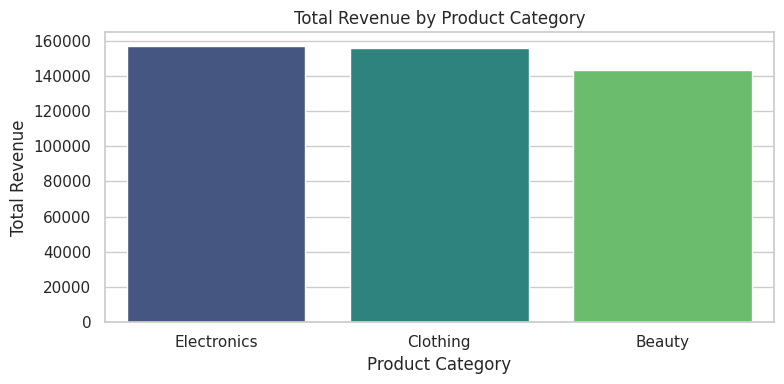

Top 10 Highest-Value Transactions:



,Transaction ID,Date,Product Category,Quantity,Price per Unit,Total Amount
14,15,2023-01-16,Electronics,4,500,2000
64,65,2023-12-05,Electronics,4,500,2000
71,72,2023-05-23,Electronics,4,500,2000
73,74,2023-11-22,Beauty,4,500,2000
88,89,2023-10-01,Electronics,4,500,2000
92,93,2023-07-14,Beauty,4,500,2000
108,109,2023-10-18,Electronics,4,500,2000
117,118,2023-05-16,Electronics,4,500,2000
123,124,2023-10-27,Clothing,4,500,2000
138,139,2023-12-15,Beauty,4,500,2000


In [5]:
# Revenue by Product Category
category_sales = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(8, 4))
sns.barplot(data=category_sales, x='Product Category', y='Total Amount', hue='Product Category', palette='viridis', legend=False)
plt.title('Total Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.tight_layout()
plt.show()

# Top 10 Highest-Value Orders
top_10_orders = df.nlargest(10, 'Total Amount')[['Transaction ID', 'Date', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']]
print("Top 10 Highest-Value Transactions:\n")
display(top_10_orders)

### Observation — Product Performance
* **Category Revenue:** **Electronics** leads in total revenue generation, closely followed by **Clothing** and **Beauty**.
* **High-Value Transactions:** The top-performing individual transactions reach up to 2,000, driven by multi-unit purchases (Quantity = 4) of high-ticket items (Price per Unit = 500).

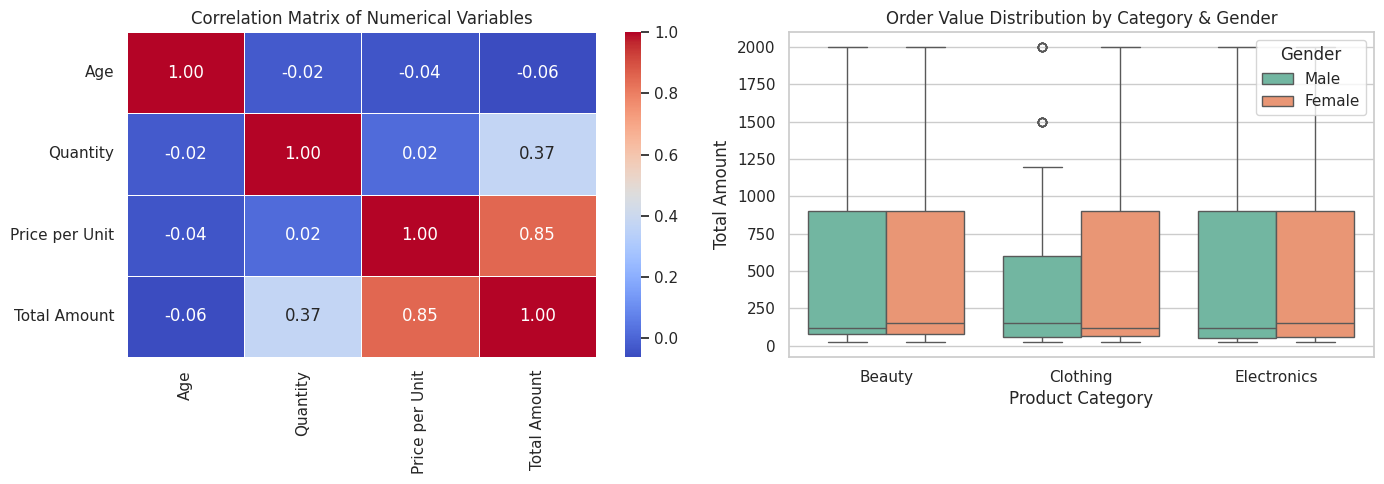

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Correlation Matrix Heatmap
numeric_cols = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']]
corr_matrix = numeric_cols.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=axes[0])
axes[0].set_title('Correlation Matrix of Numerical Variables')

# 2. Additional Insight: Spending by Category and Gender
sns.boxplot(data=df, x='Product Category', y='Total Amount', hue='Gender', palette='Set2', ax=axes[1])
axes[1].set_title('Order Value Distribution by Category & Gender')
axes[1].set_xlabel('Product Category')
axes[1].set_ylabel('Total Amount')

plt.tight_layout()
plt.show()

### Observation — Correlation & Demographic Spending
* **Correlation Matrix:** `Total Amount` has a strong positive correlation with `Price per Unit` (0.85) and a moderate positive correlation with `Quantity` (0.37). Customer `Age` shows virtually zero linear correlation (-0.06) with total spending.
* **Category vs. Gender Spending:** Median spending in **Beauty** and **Electronics** shows distinct distribution spreads across male and female customers, indicating opportunities for targeted category promotions.

## Conclusion & Actionable Business Recommendations

Based on the exploratory analysis of the 1,000 retail transactions, here are three data-driven recommendations to grow revenue:

1. **Seasonal Inventory & Promotional Timing:** Since revenue peaks in Q2 and Q4 (especially May and October) and dips in March and September, management should increase stock levels ahead of peak months and run targeted discount campaigns during slower months to stabilize cash flow.
2. **Focus on High-Ticket Bundling in Electronics & Clothing:** Because `Price per Unit` is the strongest driver of total order value (r = 0.85), introducing product bundles (e.g., accessories paired with core Electronics or Clothing items) can lift average `Quantity` per transaction and boost overall revenue.
3. **Age-Inclusive Digital Marketing:** With customer spending remaining consistent across all adult age groups (18–64) and an even gender split (51% Female / 49% Male), marketing campaigns should segment audiences by **product category preference** rather than restricting ad targeting to a narrow age bracket.